<center>
  <h1> <strong> Análise de Otimização </strong> </h1>
  <h3> U-Net Clássica D2: MoS2 (dados completos) </h3>
  <b>Júlia Guedes A. dos Santos & Yasmin B. Shimizu</b>
</center>
 
 
<p style="text-align: center;">
  Parte do Trabalho de Conclusão de Curso <b>Redes neurais clássicas e fuzzy para segmentação de imagens de microscopia eletrônica: desempenho e impactos socioambientais</b>, desenvolvido na Ilum Escola de Ciência do Centro Nacional de Pesquisa em Energia e Materiais (CNPEM) para obtenção do título de Bacharel em Ciência e Tecnologia.
</p>
 
<center>
  <img src="https://github.com/yasminbshimizu/FP-UNet_TEM/blob/main/imagens_README/logos_ilumcnpem.png?raw=true" width="1000"/>
</center>

### **Importação de bibliotecas**

In [1]:
import torch
import pickle
import io
import random

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import numpy as np
import seaborn as sns
from torch.utils.data import TensorDataset, DataLoader
from torchmetrics import Accuracy, Recall, Precision, Specificity, F1Score
from torchmetrics.segmentation import DiceScore
import torchmetrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc

### **Parâmetros do plot**

In [2]:
plt.rcParams.update({
    # "text.usetex": True,           
    "font.size": 12,                
    "axes.labelsize": 14,          
    "axes.titlesize": 14,
    "xtick.labelsize": 12,          
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 16,
    "figure.dpi": 300,              
    "savefig.dpi": 300              
})

### **Análise Perda**

In [3]:
df_otimizado =  pd.read_csv("../../3_Otimização-de-Hiperparâmetros/3_4_Análise-de-resultados/3_4_2_MoS2/3_4_2_1_DFs-perdas/perdas_otimizacao1_unetd2_mos2_dados_completos.csv")

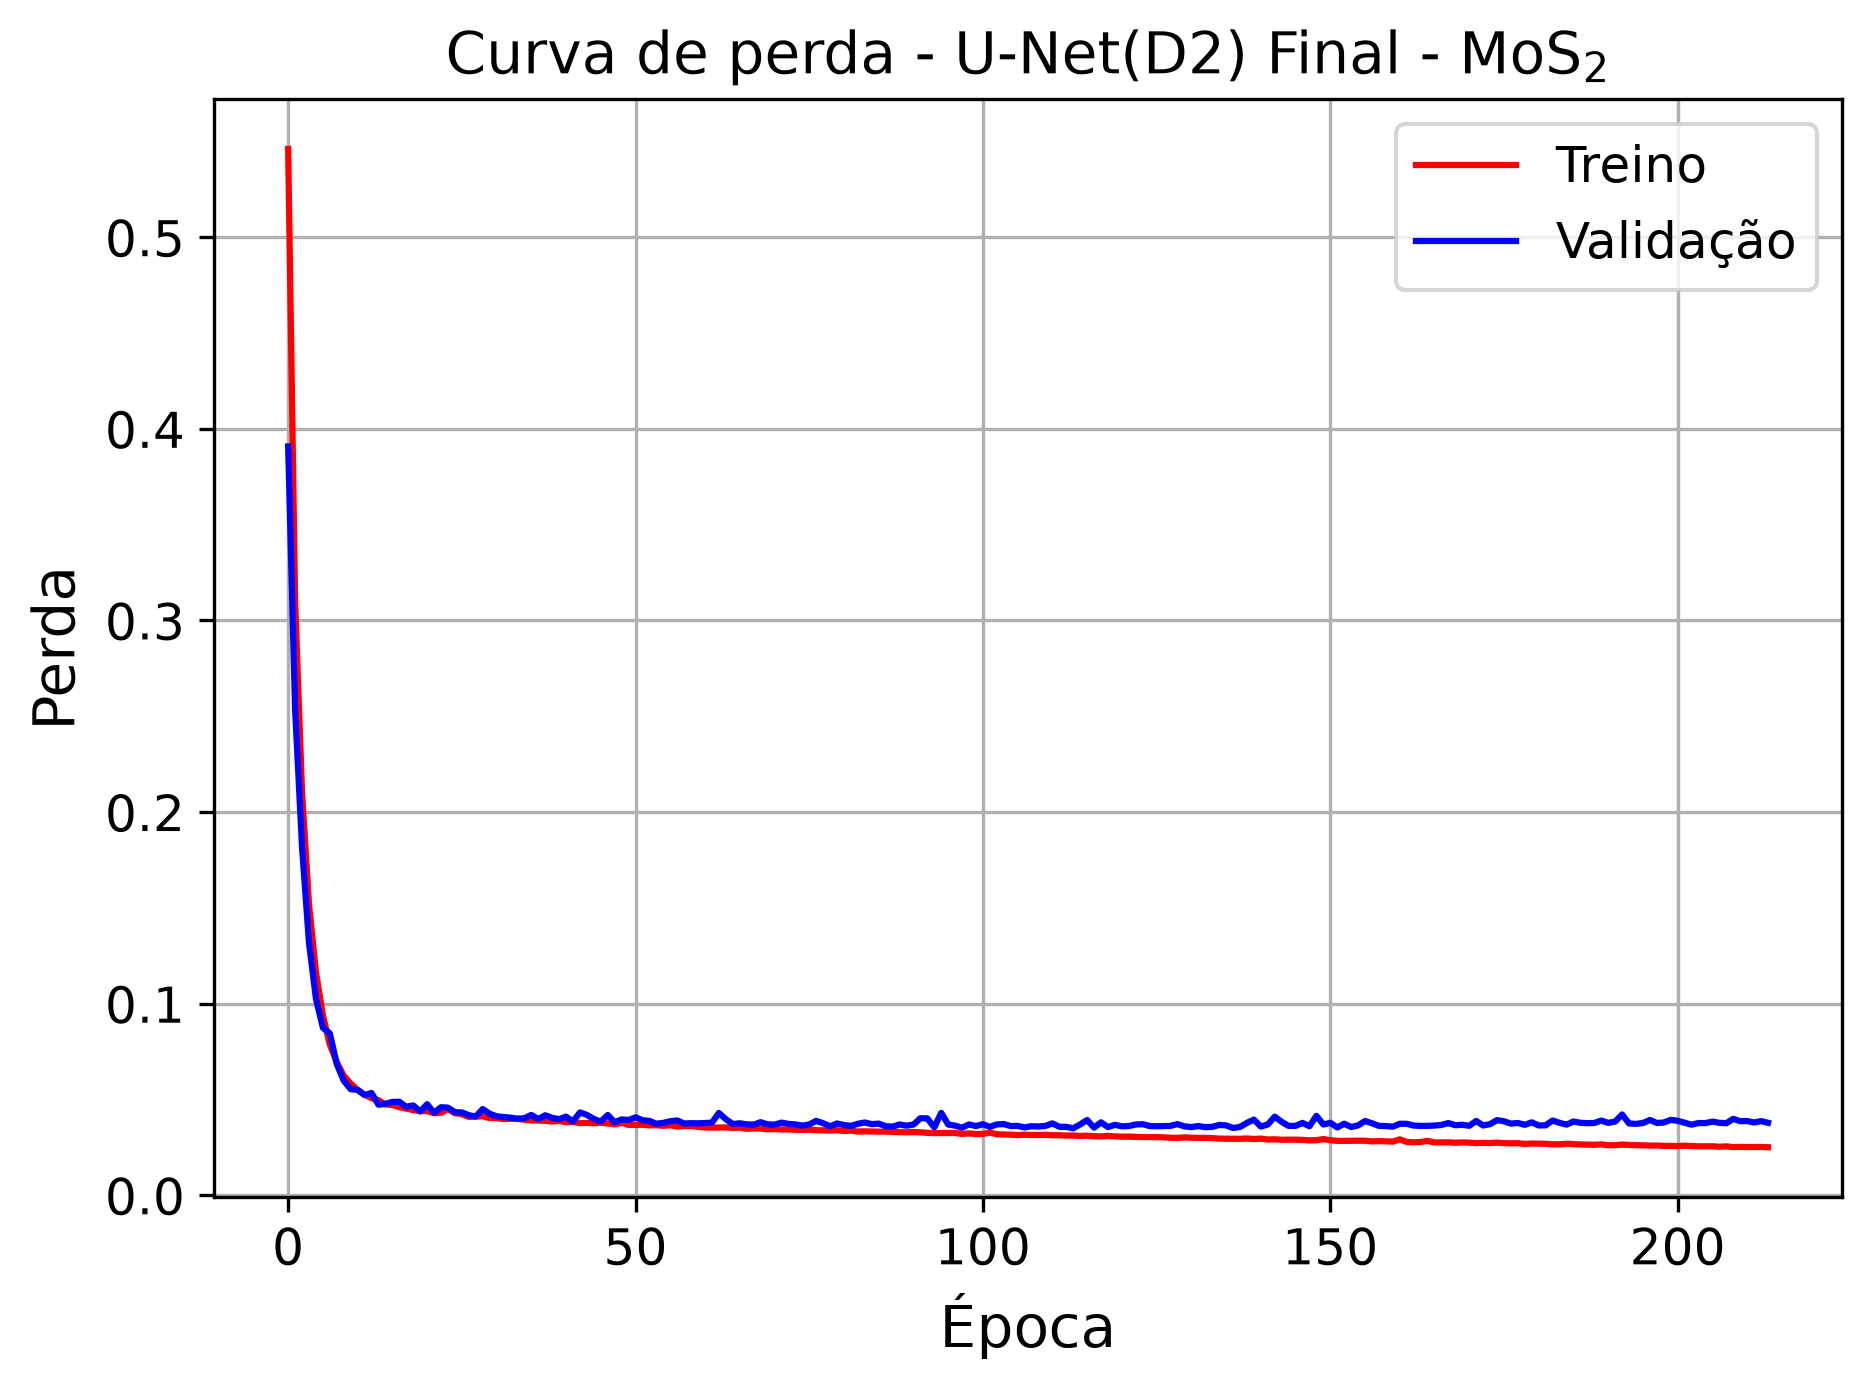

In [4]:
x0 = pontos = np.linspace(0, len(df_otimizado["Treino"]) - 1, num=len(df_otimizado["Treino"]))

x1 = pontos = np.linspace(0, len(df_otimizado["Treino"]) - 1, num=len(df_otimizado["Treino"]))
plt.plot(x1, df_otimizado["Treino"], color="Red", label="Treino")
plt.plot(x1, df_otimizado["Validação"], color="Blue", label="Validação")
plt.legend()
plt.title(r"Curva de perda - U-Net(D2) Final - MoS$_2$")
plt.ylabel("Perda")
plt.xlabel("Época")
plt.grid(0.3)

plt.tight_layout()

plt.savefig(
    "Imagens/curva_aprendizado_unetd2_final_mos2.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### **Carregamento dos dados**

In [5]:
dados_mos2 = np.load(
        "../../../Datasets_finais/mos2_test_final.npz"
        )

print("Carregou os dados", flush=True)

imagens_mos2 = dados_mos2["image"].astype(np.float32)
mascaras_mos2 = dados_mos2["labels"].astype(np.float32)

del dados_mos2

print("Carregou imagens e rótulos", flush=True)

print("imagens:", imagens_mos2.shape, imagens_mos2.dtype, imagens_mos2.nbytes / 1024**3, "GB")
print("mascaras:", mascaras_mos2.shape, mascaras_mos2.dtype, mascaras_mos2.nbytes / 1024**3, "GB")

imagens_mos2 = torch.from_numpy(imagens_mos2)

mascaras_mos2 = torch.from_numpy(mascaras_mos2)

if imagens_mos2.ndim == 3:

    imagens_mos2 = imagens_mos2.unsqueeze(1)

if mascaras_mos2.ndim == 3:

    mascaras_mos2 = mascaras_mos2.unsqueeze(1)

dataset_mos2 = TensorDataset(imagens_mos2, mascaras_mos2)

loader_mos2 = DataLoader(
    dataset_mos2,
    batch_size=8,
    shuffle=False
)

Carregou os dados
Carregou imagens e rótulos
imagens: (1000, 1, 512, 512) float32 0.9765625 GB
mascaras: (1000, 1, 512, 512) float32 0.9765625 GB


### **U-Net MaxPool Grafeno (D2)**

In [6]:
# Salva a função original
_load_from_bytes_original_ = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("../../3_Otimização-de-Hiperparâmetros/3_3_Redes-Treinadas/3_3_2_MoS2/U_Net_MaxPool_mos2_dados_completos.pkl", "rb") as modelo:
        UNet_mos2_otimizada  = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original_

UNet_mos2_otimizada = UNet_mos2_otimizada.to("cpu")
UNet_mos2_otimizada.eval()

UNet_MulticlasseD2(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU6(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_ru

### **Previsões**

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

acuracia_multiclasse = Accuracy(task="multiclass", num_classes=3, average=None).to(device)
sensibilidade_multiclasse = Recall(task="multiclass", num_classes=3, average=None).to(device)
especificidade_multiclasse = Specificity(task="multiclass", num_classes=3, average=None).to(device)
precisao_multiclasse = Precision(task="multiclass", num_classes=3, average=None).to(device)
f1_multiclasse = F1Score(task="multiclass", num_classes=3, average=None).to(device)
dice_multiclasse = DiceScore(num_classes=3, include_background=True, average=None, input_format="index").to(device)

In [8]:
acuracia_multiclasse.reset()
sensibilidade_multiclasse.reset()
especificidade_multiclasse.reset()
precisao_multiclasse.reset()
f1_multiclasse.reset()
dice_multiclasse.reset()

previsoes_mos2_otimizada = []
rotulos_reais_mos2_otimizada = []

with torch.no_grad():

    for imgs, mascaras in loader_mos2:

        imgs = imgs.to(device)
        mascaras = mascaras.to(device).long()

        if mascaras.ndim == 4 and mascaras.shape[1] == 1:
            mascaras = mascaras.squeeze(1)

        saida = UNet_mos2_otimizada(imgs)

        probs = torch.softmax(saida, dim=1)
        preds = torch.argmax(probs, dim=1)

        previsoes_mos2_otimizada.extend(preds.cpu().numpy())
        rotulos_reais_mos2_otimizada.extend(mascaras.cpu().numpy())

        acuracia_multiclasse.update(preds, mascaras)
        sensibilidade_multiclasse.update(preds, mascaras)
        especificidade_multiclasse.update(preds, mascaras)
        precisao_multiclasse.update(preds, mascaras)
        f1_multiclasse.update(preds, mascaras)
        dice_multiclasse.update(preds, mascaras)

acuracia_mos2_otimizada = acuracia_multiclasse.compute().cpu().tolist()
sensibilidade_mos2_otimizada = sensibilidade_multiclasse.compute().cpu().tolist()
especificidade_mos2_otimizada = especificidade_multiclasse.compute().cpu().tolist()
precisao_mos2_otimizada = precisao_multiclasse.compute().cpu().tolist()
f1_mos2_otimizada = f1_multiclasse.compute().cpu().tolist()
dice_mos2_otimizada = dice_multiclasse.compute().cpu().tolist()

### **Análise de resultados**

##### **Métricas**

In [9]:
acc0_mos2_otimizada = acuracia_mos2_otimizada[0]
acc1_mos2_otimizada = acuracia_mos2_otimizada[1]
acc2_mos2_otimizada = acuracia_mos2_otimizada[2]

sen0_mos2_otimizada = sensibilidade_mos2_otimizada[0]
sen1_mos2_otimizada = sensibilidade_mos2_otimizada[1]
sen2_mos2_otimizada = sensibilidade_mos2_otimizada[2]

esp0_mos2_otimizada = especificidade_mos2_otimizada[0]
esp1_mos2_otimizada = especificidade_mos2_otimizada[1]
esp2_mos2_otimizada = especificidade_mos2_otimizada[2]

pre0_mos2_otimizada = precisao_mos2_otimizada[0]
pre1_mos2_otimizada = precisao_mos2_otimizada[1]
pre2_mos2_otimizada = precisao_mos2_otimizada[2]

f1_0_mos2_otimizada = f1_mos2_otimizada[0]
f1_1_mos2_otimizada = f1_mos2_otimizada[1]
f1_2_mos2_otimizada = f1_mos2_otimizada[2]

dice_0_mos2_otimizada = dice_mos2_otimizada[0]
dice_1_mos2_otimizada = dice_mos2_otimizada[1]
dice_2_mos2_otimizada = dice_mos2_otimizada[2]

In [10]:
print(f"Classe 0: ")
print(f"Acurácia={acc0_mos2_otimizada*100:.2f}%")
print(f"Sensibilidade={sen0_mos2_otimizada*100:.2f}%")
print(f"Especificidade={esp0_mos2_otimizada*100:.2f}%")
print(f"Precisão={pre0_mos2_otimizada*100:.2f}%")
print(f"F1={f1_0_mos2_otimizada*100:.2f}%")
print(f"Dice={dice_0_mos2_otimizada*100:.2f}%")
print()

print(f"Classe 1: ")
print(f"Acurácia={acc1_mos2_otimizada*100:.2f}%")
print(f"Sensibilidade={sen1_mos2_otimizada*100:.2f}%")
print(f"Especificidade={esp1_mos2_otimizada*100:.2f}%")
print(f"Precisão={pre1_mos2_otimizada*100:.2f}%")
print(f"F1={f1_1_mos2_otimizada*100:.2f}%")
print(f"Dice={dice_1_mos2_otimizada*100:.2f}%")
print()

print(f"Classe 2: ")
print(f"Acurácia={acc2_mos2_otimizada*100:.2f}%")
print(f"Sensibilidade={sen2_mos2_otimizada*100:.2f}%")
print(f"Especificidade={esp2_mos2_otimizada*100:.2f}%")
print(f"Precisão={pre2_mos2_otimizada*100:.2f}%")
print(f"F1={f1_2_mos2_otimizada*100:.2f}%")
print(f"Dice={dice_2_mos2_otimizada*100:.2f}%")

Classe 0: 
Acurácia=98.55%
Sensibilidade=98.55%
Especificidade=99.61%
Precisão=96.74%
F1=97.64%
Dice=97.63%

Classe 1: 
Acurácia=97.44%
Sensibilidade=97.44%
Especificidade=99.41%
Precisão=98.54%
F1=97.99%
Dice=97.97%

Classe 2: 
Acurácia=99.07%
Sensibilidade=99.07%
Especificidade=98.26%
Precisão=98.86%
F1=98.97%
Dice=98.96%


##### **Matriz de confusão**

In [11]:
confmat_multiclasse = torchmetrics.ConfusionMatrix(
    task="multiclass",
    num_classes=3,
    normalize = "all"
).to(device)

In [12]:
previsoes_array_mos2_otimizada = np.asarray(previsoes_mos2_otimizada)
rotulos_array_mos2_otimizada = np.asarray(rotulos_reais_mos2_otimizada)

previsoes_array_mos2_otimizada = previsoes_array_mos2_otimizada.astype(np.float64)
rotulos_array_mos2_otimizada = rotulos_array_mos2_otimizada.astype(np.int64)

previsoes_tensor_mos2_otimizada = torch.tensor(
    previsoes_array_mos2_otimizada,
    dtype=torch.long,
    device=device
)

rotulos_tensor_mos2_otimizada = torch.tensor(
    rotulos_array_mos2_otimizada,
    dtype=torch.long,
    device=device
)

if previsoes_tensor_mos2_otimizada.ndim == 4 and previsoes_tensor_mos2_otimizada.shape[1] == 1:
    previsoes_tensor_mos2_otimizada = previsoes_tensor_mos2_otimizada.squeeze(1)

if rotulos_tensor_mos2_otimizada.ndim == 4 and rotulos_tensor_mos2_otimizada.shape[1] == 1:
    rotulos_tensor_mos2_otimizada = rotulos_tensor_mos2_otimizada.squeeze(1)

cm_mos2_otimizada = confmat_multiclasse(
    previsoes_tensor_mos2_otimizada,
    rotulos_tensor_mos2_otimizada
)

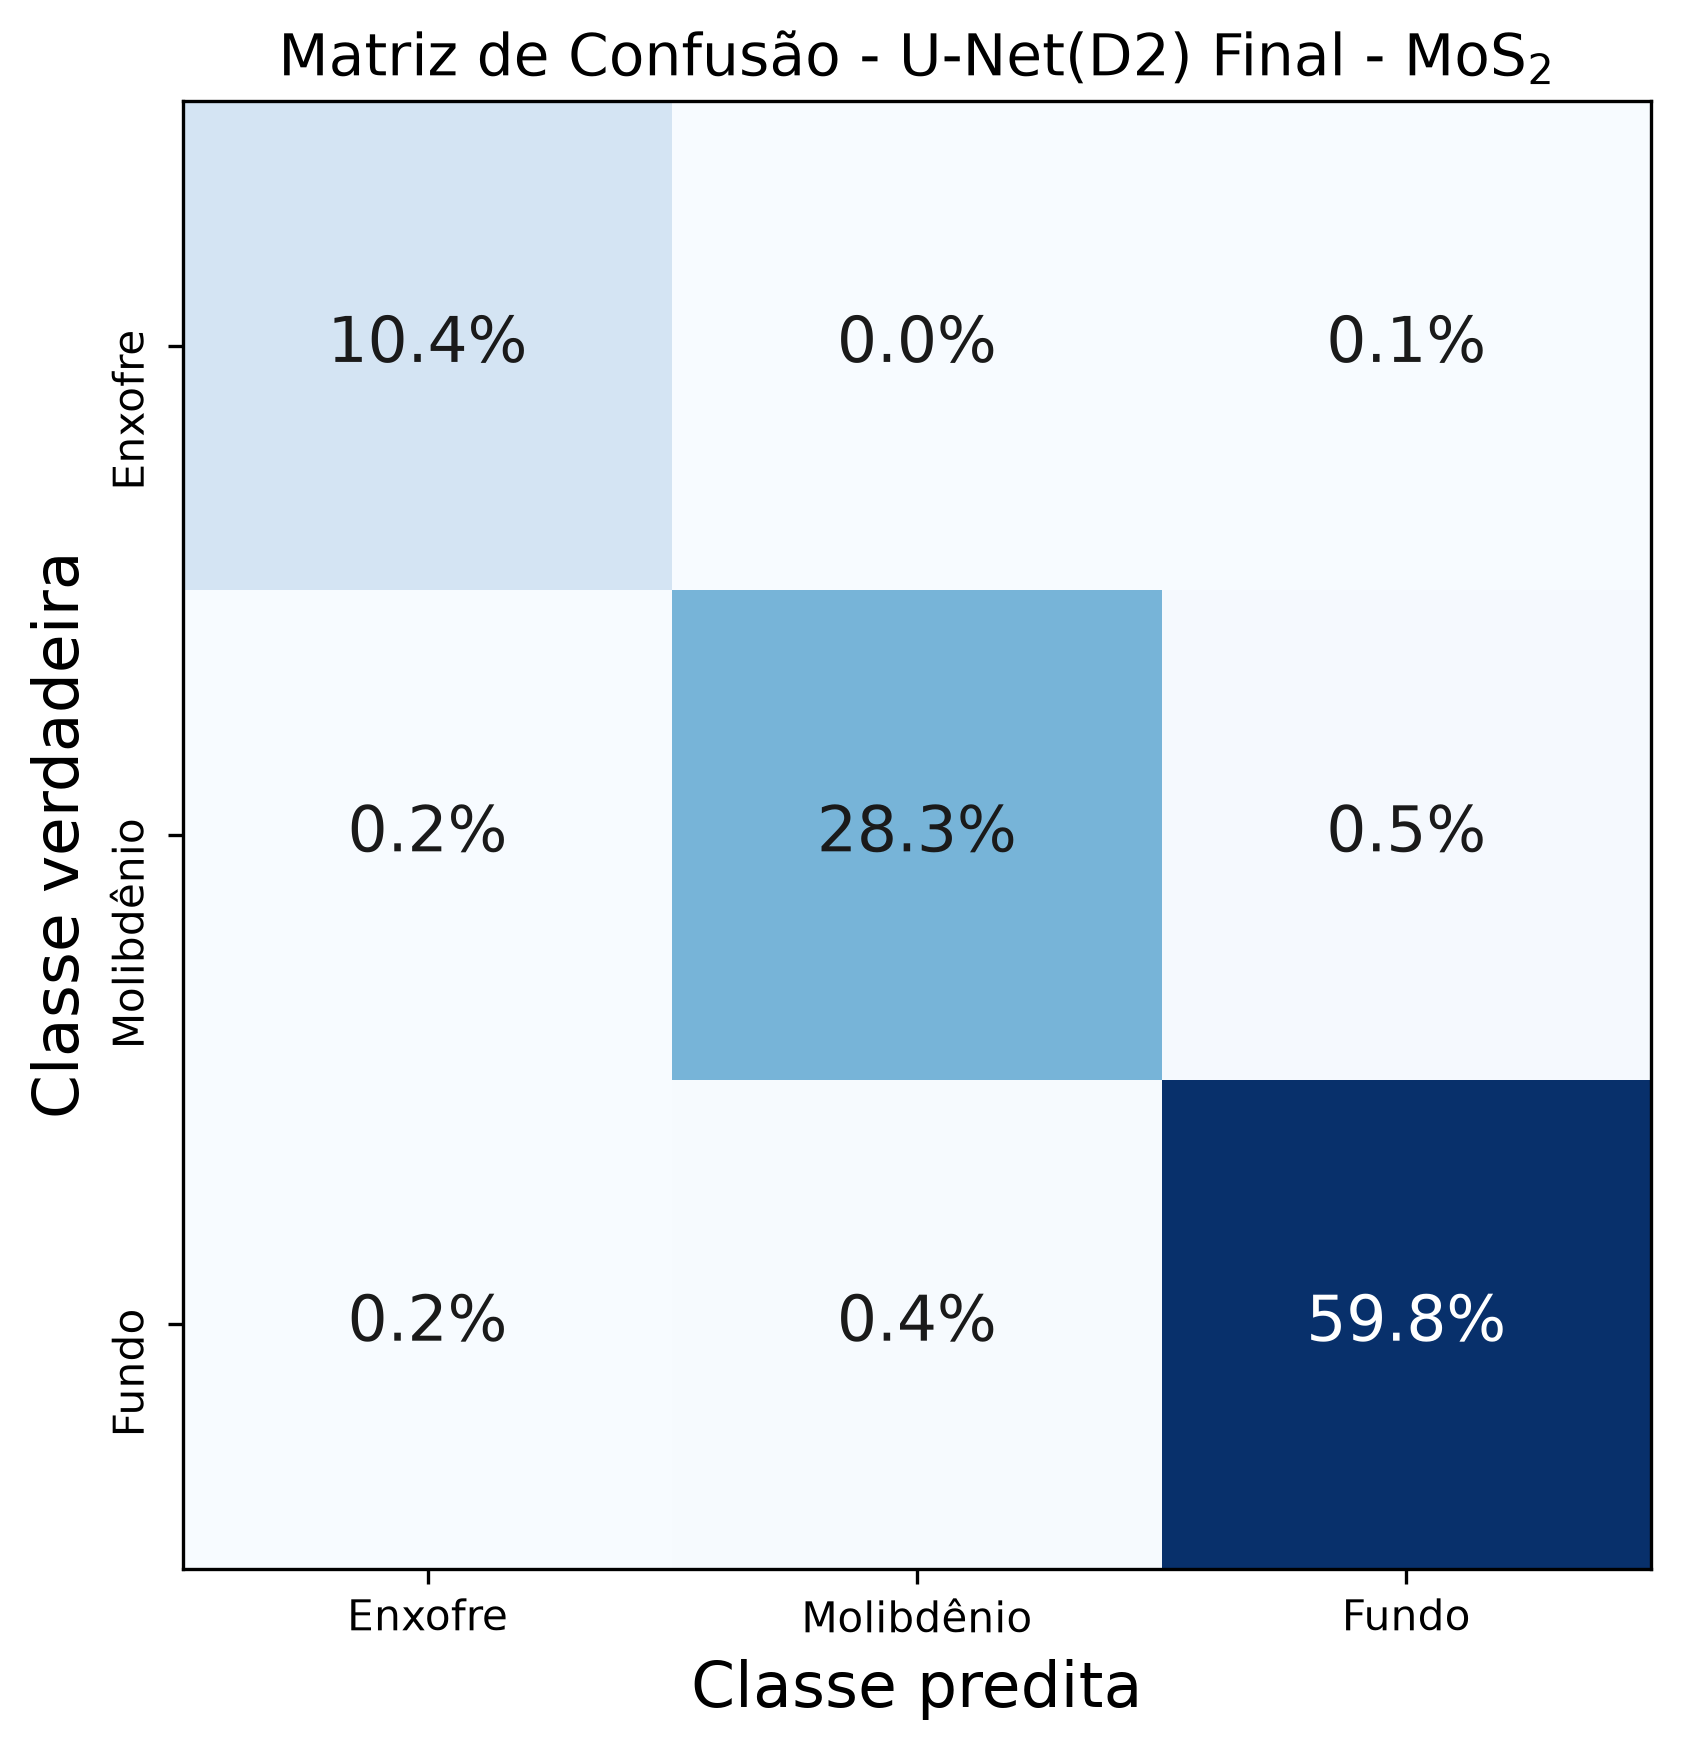

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

confmat_multiclasse.plot(
    cm_mos2_otimizada,
    ax=ax,
    cmap="Blues",
    add_text=True
)

ax.set_title(r"Matriz de Confusão - U-Net(D2) Final - MoS$_2$")
ax.set_ylabel("Classe verdadeira")
ax.set_xlabel("Classe predita")

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["Enxofre", "Molibdênio", "Fundo"], rotation=0)

ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Enxofre", "Molibdênio", "Fundo"], rotation=90)

# Converte os valores da matriz de confusão em porcentagens
for texto, valor in zip(ax.texts, cm_mos2_otimizada.flatten()):
    texto.set_text(f"{valor.item() * 100:.1f}%")

plt.tight_layout()

plt.savefig(
    "Imagens/matriz_confusao_unetd2_final_mos2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### **Sobreposição entre a imagem real e a máscara**

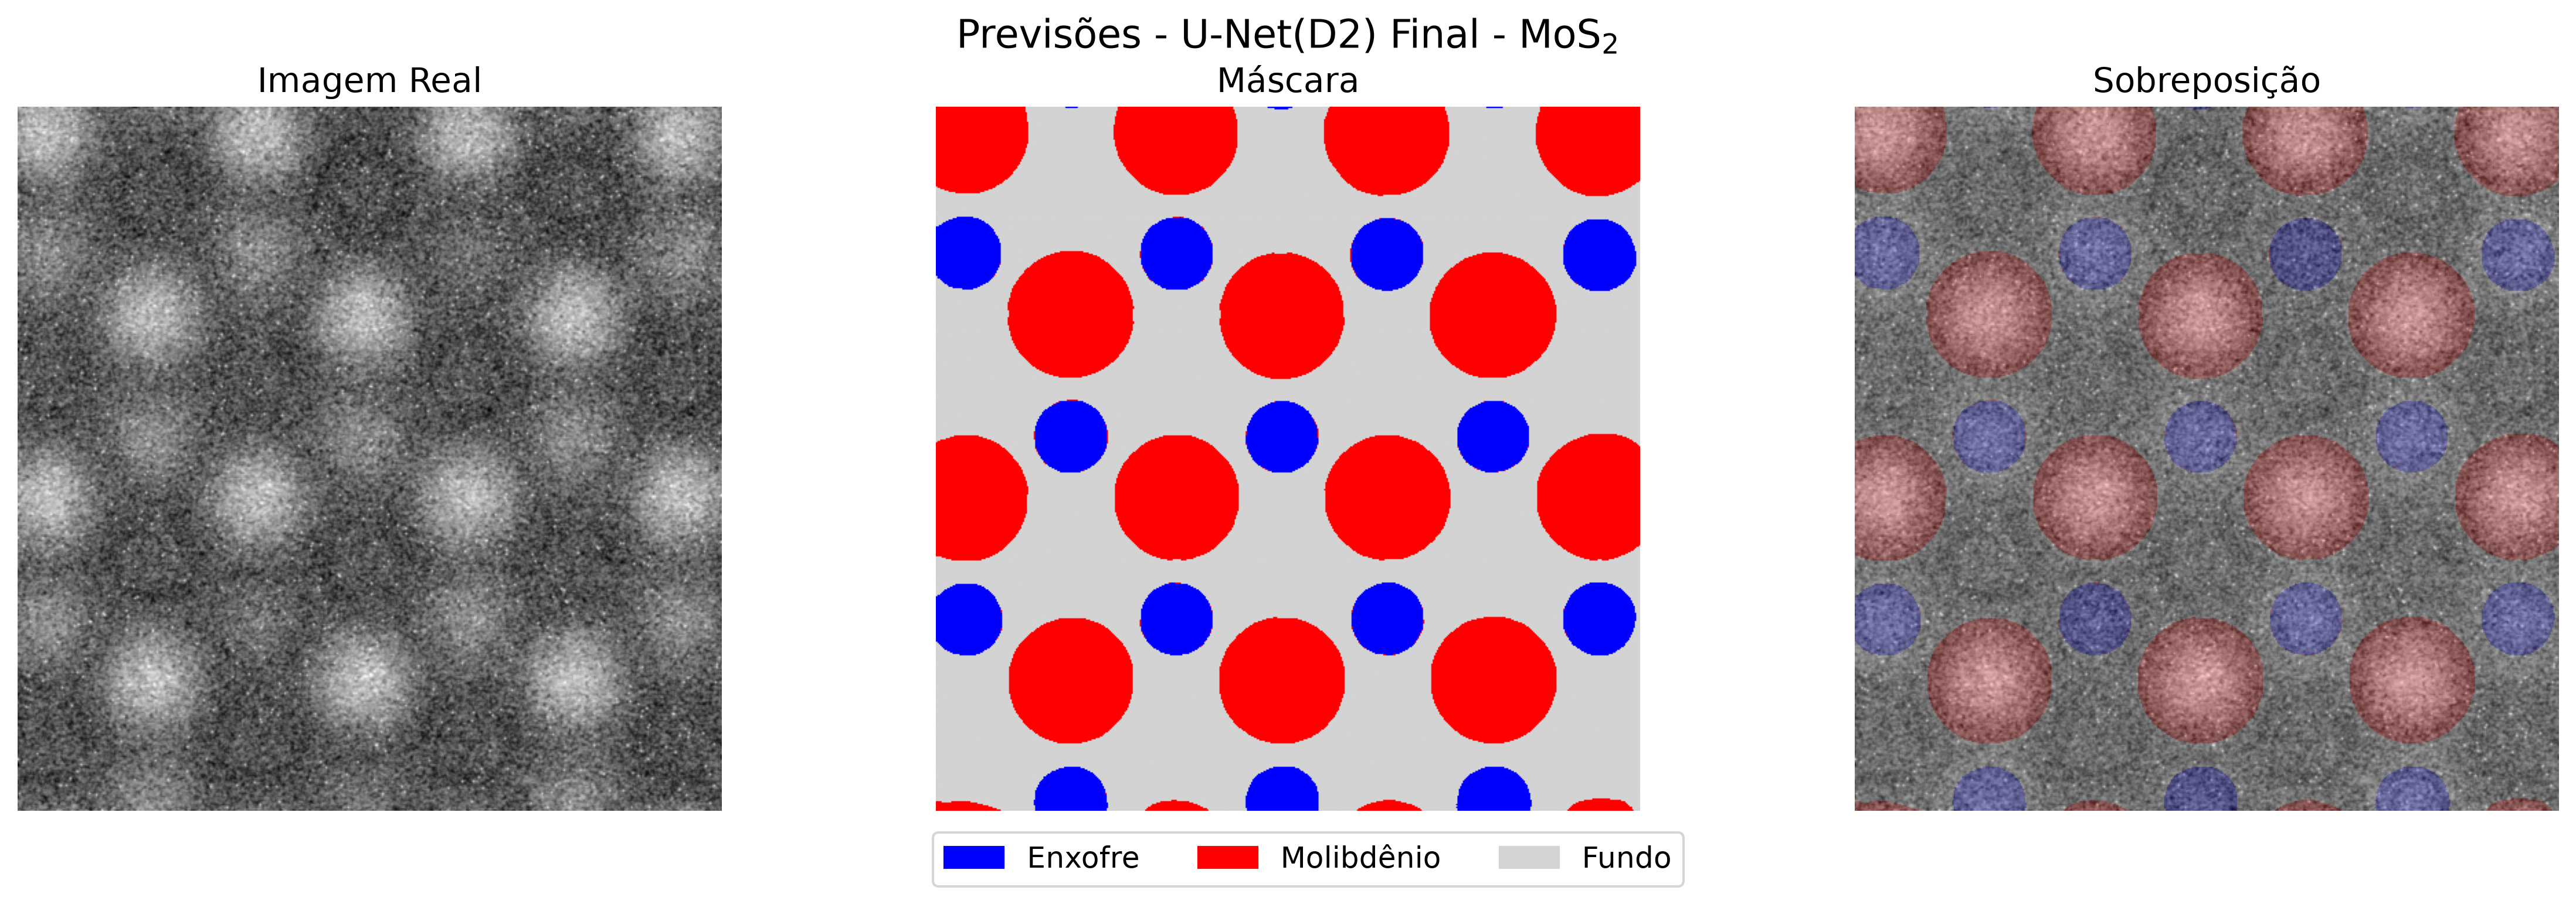

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colormap_mos2 = ListedColormap(["blue", "red", "lightgray"])

axes[0].imshow(imagens_mos2[0][0], cmap="gray")
axes[0].set_title("Imagem Real")
axes[0].axis("off")

axes[1].imshow(previsoes_mos2_otimizada[0], origin='upper', cmap=colormap_mos2)
axes[1].set_title("Máscara")
axes[1].axis("off")

legenda0 = mpatches.Patch(color="blue", label="Enxofre")
legenda1 = mpatches.Patch(color="red", label="Molibdênio")
legenda2 = mpatches.Patch(color="lightgray", label="Fundo")


axes[1].legend(
    handles=[legenda0, legenda1, legenda2],
    loc="upper left",
    fontsize=12,
    bbox_to_anchor=(-0.025, -0.01),
    ncols=3)

axes[2].imshow(imagens_mos2[0][0], cmap="gray")
axes[2].imshow(previsoes_mos2_otimizada[0], origin='upper', alpha=0.2, cmap=colormap_mos2)

axes[2].set_title("Sobreposição")
axes[2].axis("off")

plt.suptitle(r"Previsões - U-Net(D2) Final - MoS$_2$")

plt.tight_layout()

plt.savefig(
    "Imagens/previsao_unetd2_final_mos2.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

##### **Gráfico de subtração**

In [15]:
grafico_sobreposicao_otimizada = np.zeros_like(mascaras_mos2[0][0])

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 0),
    0,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 1),
    1,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 2),
    2,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 1) & (previsoes_mos2_otimizada[0] == 0),
    3,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 1) & (previsoes_mos2_otimizada[0] == 1),
    4,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 1) & (previsoes_mos2_otimizada[0] == 2),
    5,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 2) & (previsoes_mos2_otimizada[0] == 0),
    6,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 2) & (previsoes_mos2_otimizada[0] == 1),
    7,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_mos2[0][0] == 2) & (previsoes_mos2_otimizada[0] == 2),
    8,
    grafico_sobreposicao_otimizada
)

C:\Users\julia24002\AppData\Local\Temp\ipykernel_13864\1551062620.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 0),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_13864\1551062620.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 1),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_13864\1551062620.py:16: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 2),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_13864\1551062620.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in

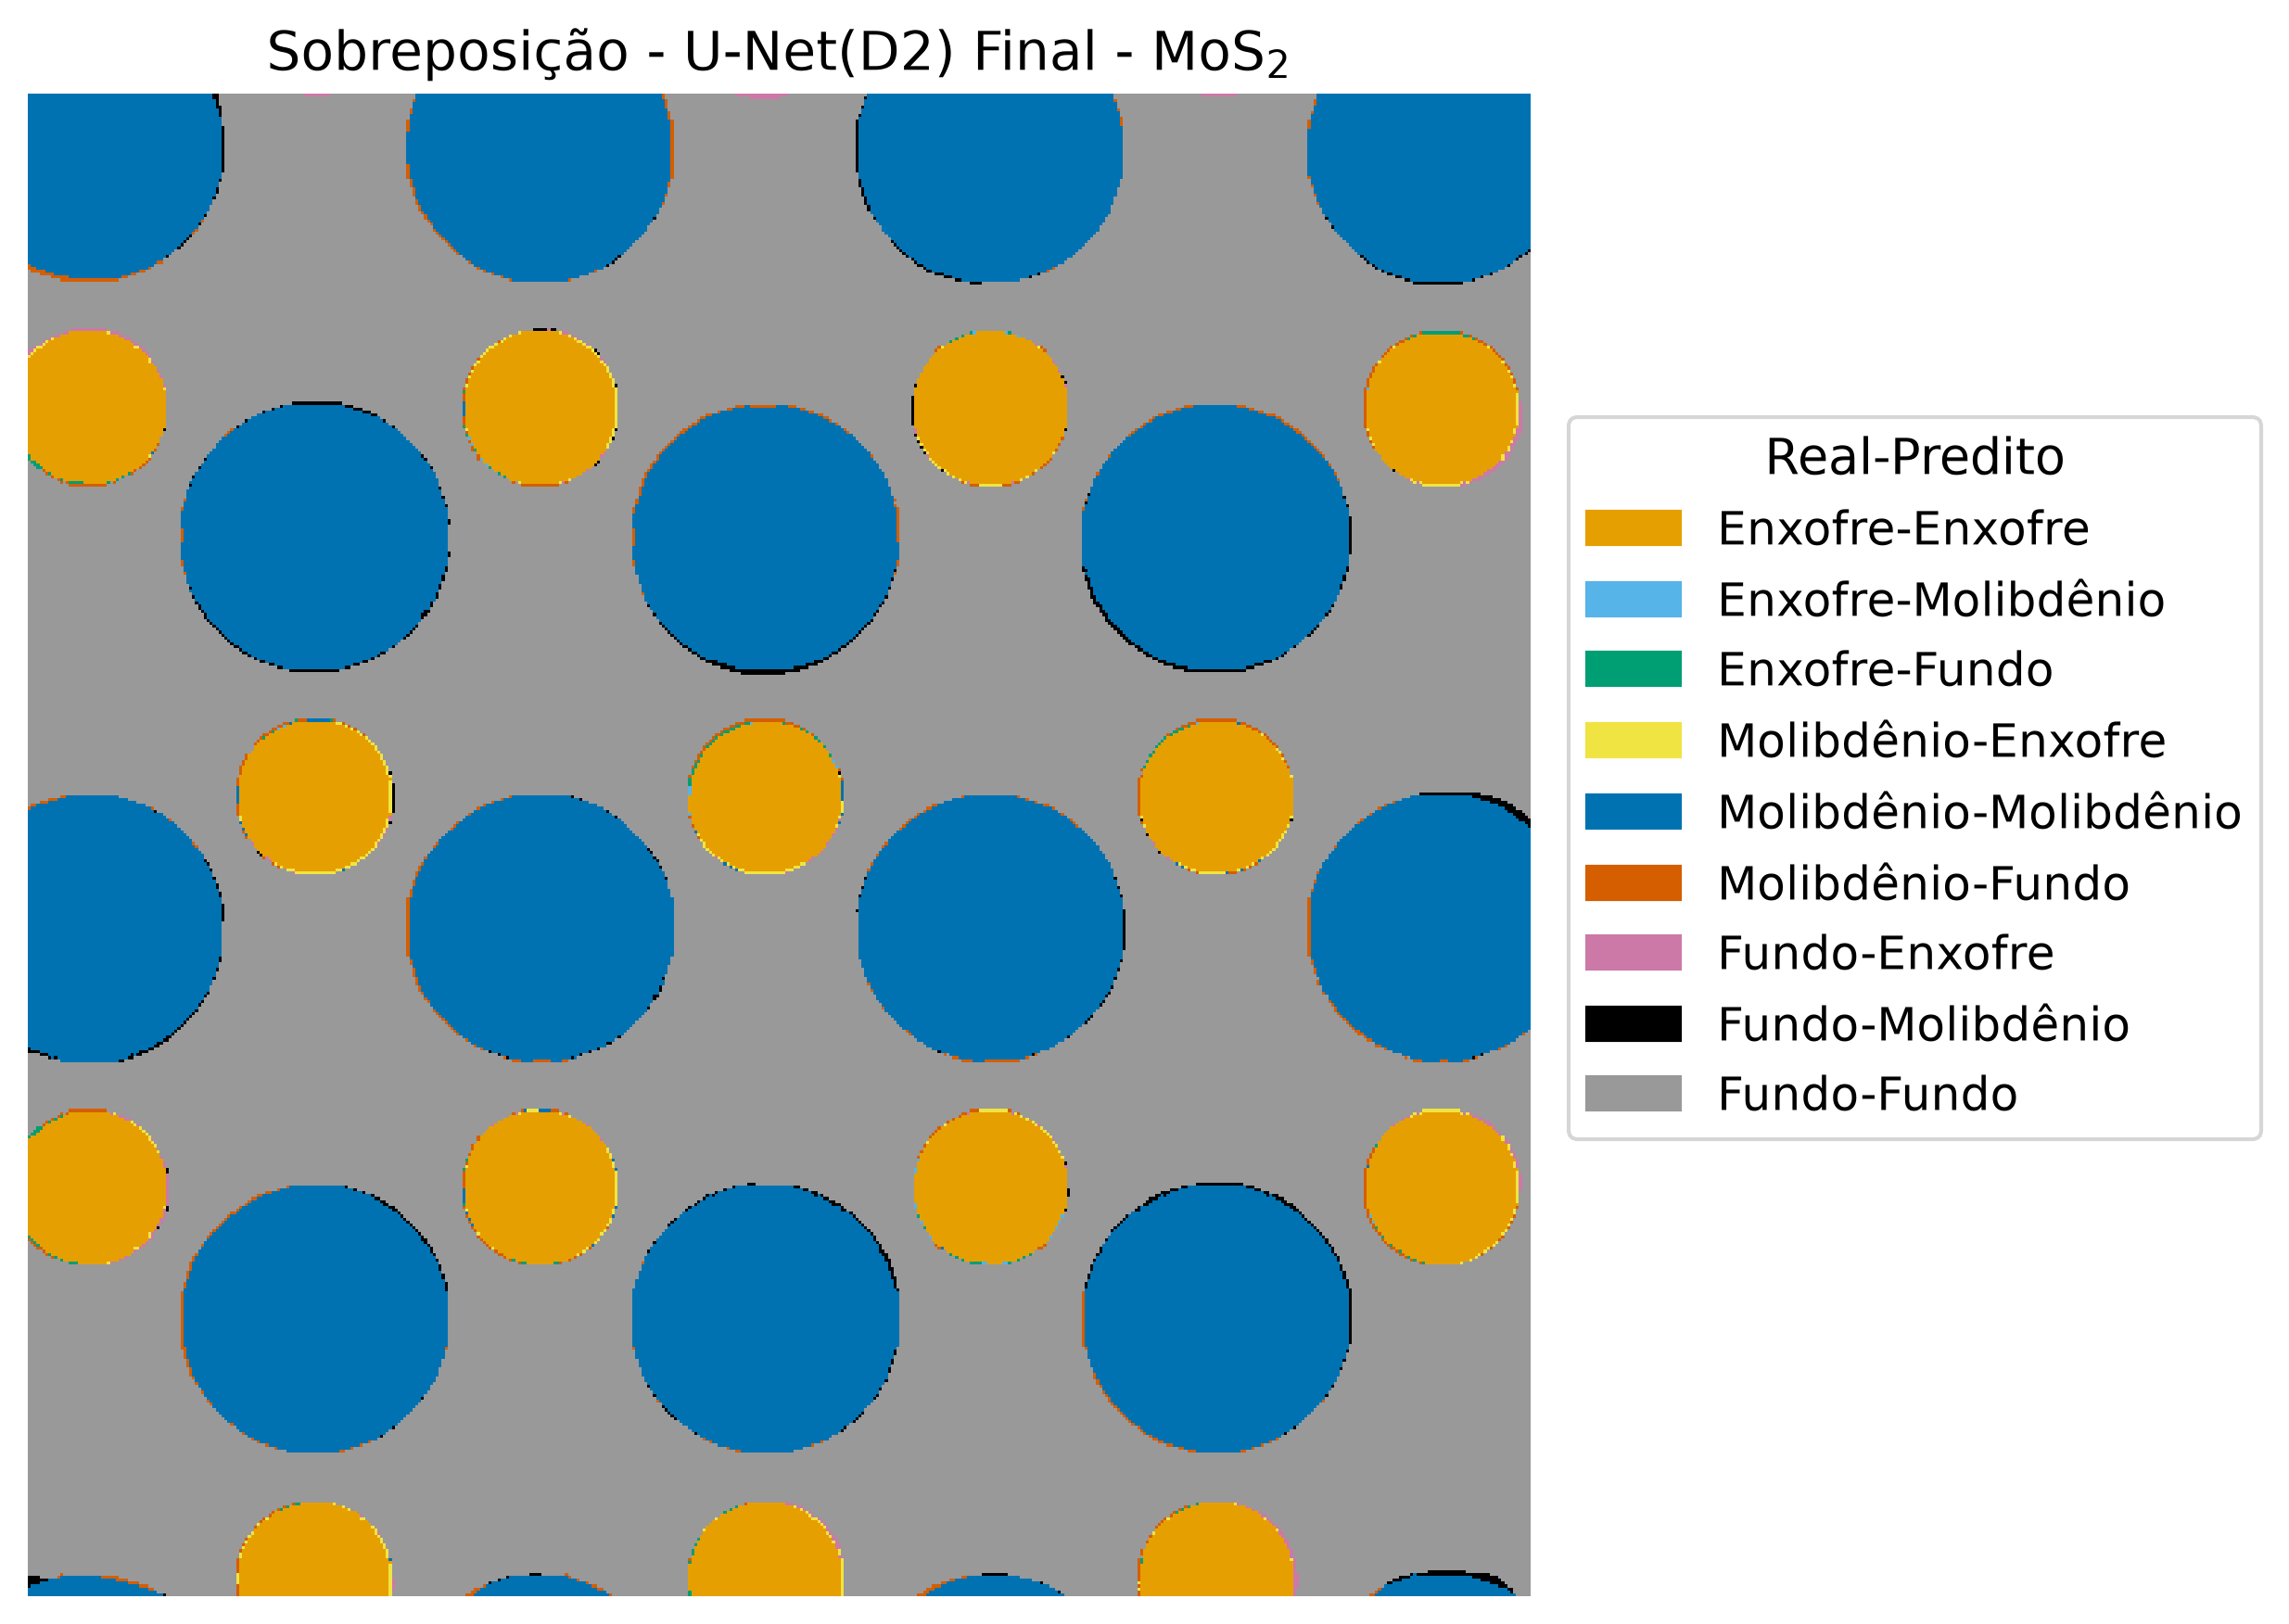

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))

okabe_ito = ListedColormap([
    "#e69f00",
    "#56b4e9",
    "#009e73",
    "#f0e442",
    "#0072b2",
    "#d55e00",
    "#cc79a7",
    "#000000",
    "#999999"
])

legenda0 = mpatches.Patch(color="#e69f00", label="Enxofre-Enxofre")
legenda1 = mpatches.Patch(color="#56b4e9", label="Enxofre-Molibdênio")
legenda2 = mpatches.Patch(color="#009e73", label="Enxofre-Fundo")
legenda3 = mpatches.Patch(color="#f0e442", label="Molibdênio-Enxofre")
legenda4 = mpatches.Patch(color="#0072b2", label="Molibdênio-Molibdênio")
legenda5 = mpatches.Patch(color="#d55e00", label="Molibdênio-Fundo")
legenda6 = mpatches.Patch(color="#cc79a7", label="Fundo-Enxofre")
legenda7 = mpatches.Patch(color="#000000", label="Fundo-Molibdênio")
legenda8 = mpatches.Patch(color="#999999", label="Fundo-Fundo")


ax.legend(
    handles=[
        legenda0, legenda1, legenda2,
        legenda3, legenda4, legenda5,
        legenda6, legenda7, legenda8
    ],
    loc="upper left",
    fontsize=12,
    bbox_to_anchor=(1.01, 0.8),
    ncols=1,
    title="Real-Predito",
    title_fontsize=13
)

ax.imshow(
    grafico_sobreposicao_otimizada,
    origin="upper",
    cmap=okabe_ito
)

ax.set_title(r"Sobreposição - U-Net(D2) Final - MoS$_2$")
ax.axis("off")


plt.tight_layout()
plt.savefig(
    "Imagens/sobreposicao_unetd2_final_mos2.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()